In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# %% 1. Settings: instantaneous local temperature versus an average of global R lags
import numpy as np
import xarray as xr
from pathlib import Path

lag_core = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412")
lag_raw_root = Path("/scratch/leiff/MCA/amip_clean/data")
lag_start, lag_end, lag_ddof = "2000-03", "2014-12", 1
lag_cases = {"instantaneous": [0], "0_to_6": list(range(7)), "0_to_12": list(range(13)),
             "minus6_to_6": list(range(-6, 7)), "minus12_to_12": list(range(-12, 13))}
lag_labels = {"instantaneous": "Instantaneous", "0_to_6": "Mean R: lags 0 to +6",
              "0_to_12": "Mean R: lags 0 to +12", "minus6_to_6": "Mean R: lags −6 to +6",
              "minus12_to_12": "Mean R: lags −12 to +12"}

# per_case keeps all 178 months in the instantaneous row. Each other row keeps
# every t for which ALL its requested R(t+lag) dates lie within the raw period.
# common instead uses the SAME 154 temperature dates in every default row;
# it isolates response averaging from changed sampling, detrending and T SD.
lag_sample_mode = "per_case"         # Or "common" for identical dates and Zi across rows.
lag_run_name = "run_01"
lag_output_dir = lag_core / "global_r_lag_comparison" / f"{lag_start}_{lag_end}_{lag_sample_mode}" / lag_run_name
lag_archive_path = lag_output_dir / "global_r_lag_comparison.npy"
lag_obs_paths = {"T": lag_raw_root / "ERA5/tas_194001-202412_g025.nc",
                 "R": lag_raw_root / "CERES/CERES_net_200003-202604_g025.nc"}
lag_map_mask = None                 # Optional extra output mask; does NOT change global R weights.
lag_save, lag_resume = True, True   # Completed MODEL checkpoints; unfinished models restart.
lag_preprocessing_tag = "raw_offset_mean_then_monthwise_detrend_v1"

# The default map is the original covRTi diagnostic: Cov(Ti/sigma_Ti, R).
# All 15 panels share one physical-unit color scale. No old significance masks
# are reused: those classifications do not apply to these changed diagnostics.
lag_plot_quantity = "cov_Zi_R"
lag_plot_method = "contourf"        # Or "pcolormesh"; native cells, no extra cyclic column.
lag_vlim, lag_percentile, lag_cmap = 0.25, 98, "RdBu_r"
# lag_cmap = "cmr.fusion_r"         # Imports cmasher in the plotting function if selected.
lag_figsize, lag_font_scale, lag_save_figure = (15, 15), 1., True

# Import/paste YOUR detrend_monthly_fast before cell 4. It must accept (time,...)
# with arbitrary starting months/partial years. No replacement detrend is supplied.
# Calculate/save: cells 1–6. Later load/plot only: cells 1, 7, 8, 9.




In [4]:
# %% 2. Small helpers for dates, file alignment, safe saving and finite means
def lag_date_positions(months, cases, sample_mode="per_case"):
    """Return actual index/response dates; offsets are inclusive, integer months."""
    months = np.asarray(months, dtype="datetime64[M]")
    if sample_mode not in ["per_case", "common"] or not cases:
        raise ValueError("Choose per_case or common, with at least one lag case.")
    if months.ndim != 1 or np.isnat(months).any() or np.any(np.diff(months.astype(int)) != 1):
        raise ValueError("Expected a consecutive monthly time axis.")
    offsets = {}
    for case, values in cases.items():
        if any(isinstance(v, (bool, np.bool_)) for v in np.asarray(values, dtype=object).ravel()):
            raise ValueError(f"{case}: offsets cannot be booleans.")
        a = np.asarray(values)
        if a.ndim != 1 or not a.size or a.dtype.kind not in "iu" or len(np.unique(a)) != len(a):
            raise ValueError(f"{case}: use unique integer offsets, e.g. list(range(7)).")
        offsets[case] = np.sort(a.astype(int))
    all_offsets = np.concatenate(list(offsets.values()))
    output = {}
    for case, a in offsets.items():
        bounds = all_offsets if sample_mode == "common" else a
        first, stop = max(0, -int(bounds.min())), len(months) - max(0, int(bounds.max()))
        if stop - first < 36:
            raise ValueError(f"{case}: fewer than 36 paired months for monthly detrending.")
        positions = np.arange(first, stop)
        output[case] = {"offsets": a, "positions": positions, "time": months[positions],
                        "response_time": months[positions[:, None] + a[None, :]], "n_pairs": len(positions)}
    return output


def lag_processed(raw, preprocess):
    """Protect inputs, then verify the user's function removes monthly means/trends."""
    raw = np.asarray(raw, dtype=float)
    result = np.asarray(preprocess(raw.copy()), dtype=float)
    if result.shape != raw.shape or not np.isfinite(result).all():
        raise ValueError("Detrending must preserve shape and handle partial endpoint years.")
    for month in range(12):
        sample = result[month::12]
        t = np.arange(len(sample), dtype=float); t -= t.mean()
        slope = np.tensordot(t, sample, axes=(0, 0)) / np.sum(t*t)
        scale = np.maximum(1., np.max(np.abs(raw[month::12]), axis=0))
        if np.any(np.abs(sample.mean(axis=0)) > 1e-8*scale) or np.any(np.abs(slope)*len(t) > 1e-8*scale):
            raise ValueError("Expected each repeated month's mean and linear trend to be removed.")
    result = result - result.mean(axis=0)
    return np.where(np.ptp(raw, axis=0) == 0, 0., result)


def lag_prepare_field(field, months, lat, lon, quantity):
    """Check source grid/calendar/units and return (member,time,lat,lon)."""
    allowed = {"T": {"K", "kelvin", "Kelvin"}, "R": {"W m-2", "W m^-2", "W m**-2", "W/m2", "W/m^2", "W m−2"}}
    unit = field.attrs.get("units")
    if unit is not None and unit not in allowed[quantity]:
        raise ValueError(f"{field.name}: convert units {unit!r} explicitly first.")
    if unit is None:
        print(f"  {field.name}: units absent; assuming {'K' if quantity == 'T' else 'W m-2'}.")
    field = field.sel(time=slice(str(months[0]), str(months[-1])))
    actual = np.asarray(field.time.dt.year*12 + field.time.dt.month - 1)
    if not np.array_equal(actual, months.astype(int) + 1970*12):
        raise ValueError(f"{field.name}: missing, duplicate, or out-of-order months.")
    for dim, expected in [("lat", lat), ("lon", lon)]:
        coordinate = np.asarray(field[dim])
        if coordinate.shape != expected.shape or not np.allclose(coordinate, expected, rtol=0, atol=1e-6):
            raise ValueError(f"{field.name}: {dim} differs from the core archive; no regridding is performed.")
    extra = [d for d in field.dims if d not in ["time", "lat", "lon"]]
    if len(extra) > 1:
        raise ValueError(f"Select extra dimensions explicitly: {field.dims}")
    if extra:
        dim = extra[0]
        if dim not in field.coords:
            print(f"  {field.name}: no member labels; using file positions.")
        ids = np.asarray(field[dim]).astype(str) if dim in field.coords else np.arange(field.sizes[dim]).astype(str)
        field = field.rename({dim: "member"}) if dim != "member" else field
        field = field.assign_coords(member=ids)
    else:
        field = field.expand_dims(member=["single"])
    if not field.sizes["member"] or len(set(field.member.values)) != field.sizes["member"]:
        raise ValueError("Empty or duplicate member IDs.")
    return field.transpose("member", "time", "lat", "lon")


def lag_finite_mean(values):
    """Arithmetic mean/count along member or model axis; retain undefined cells."""
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(values); count = valid.sum(axis=0)
    mean = np.divide(np.where(valid, values, 0.).sum(axis=0), count,
                     out=np.full(count.shape, np.nan), where=count > 0)
    return mean, count


def lag_fingerprint(value):
    import hashlib, pickle
    return hashlib.sha256(pickle.dumps(value, protocol=4)).hexdigest()


def lag_save_bundle(path, value, *, replace=False):
    """Publish only a complete file; existing results are protected by default."""
    import os, tempfile
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".tmp", delete=False) as stream:
            temporary = Path(stream.name)
            np.save(stream, value, allow_pickle=True)
            stream.flush(); os.fsync(stream.fileno())
        if replace:
            os.replace(temporary, path)
        else:
            os.link(temporary, path)
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()




In [5]:
# %% 3. One member: average raw global R over selected lags, then process and covary
def calculate_global_r_lags(T_raw, R_raw, weights, support, dates, preprocess, *, ddof=1):
    """Return one dictionary per lag case; T/R inputs are (raw_time,lat,lon).

    Ti is at t; Rbar is the mean of global R(t+lag). Neither Ti nor R is
    preprocessed on the full record first. Zi is formed AFTER paired-date
    monthwise detrending, and Rbar is NEVER standardized in cov_Zi_R.
    """
    T_raw, R_raw = [np.asarray(v, dtype=float) for v in [T_raw, R_raw]]
    weights, support = np.asarray(weights, dtype=float), np.asarray(support, dtype=bool)
    if T_raw.ndim != 3 or T_raw.shape != R_raw.shape or T_raw.shape[1:] != weights.shape or support.shape != weights.shape:
        raise ValueError("Expected matching time-first fields and 2-D weights/support.")
    if not support.any() or not np.isfinite(weights).all() or np.any(weights < 0) or not np.isclose(weights.sum(), 1.):
        raise ValueError("Need nonempty map support and fixed, normalized nonnegative global weights.")
    if not isinstance(ddof, (int, np.integer)) or ddof < 0:
        raise ValueError("ddof must be a nonnegative integer.")
    if not np.isfinite(T_raw[:, support]).all() or not np.isfinite(R_raw[:, weights > 0]).all():
        raise ValueError("Incomplete raw data on fixed temperature-map or global-radiation support.")

    # With fixed weights and complete data, averaging R globally commutes with
    # averaging its lags. Reduce to one raw global series before any lag work.
    R_global_raw = np.sum(np.where(weights > 0, R_raw, 0.) * weights, axis=(1, 2))
    results = {}
    for case, coordinate in dates.items():
        positions, offsets = coordinate["positions"], coordinate["offsets"]
        n = len(positions)
        if n <= ddof or positions.min() < 0 or positions.max() >= len(T_raw):
            raise ValueError(f"{case}: invalid paired dates/divisor.")
        response_positions = positions[:, None] + offsets[None, :]
        if response_positions.min() < 0 or response_positions.max() >= len(R_raw):
            raise ValueError(f"{case}: response dates leave the raw period.")

        # Build the raw pair FIRST. The same Ti sample/SD is used for every
        # individual lag in THIS row, making the covariance identity meaningful.
        Ti_raw = np.where(support, T_raw[positions], 0.)
        R_raw_lags = R_global_raw[response_positions]                 # (paired_time, lag)
        R_raw_mean = R_raw_lags.mean(axis=1)                          # (paired_time,)
        Ti = lag_processed(Ti_raw, preprocess)
        R_mean = lag_processed(R_raw_mean, preprocess)
        sigma_Ti, sigma_R = Ti.std(axis=0, ddof=ddof), R_mean.std(ddof=ddof)
        cov_Ti_R = np.einsum("tij,t->ij", Ti, R_mean) / (n-ddof)
        cov_Zi_R = np.divide(cov_Ti_R, sigma_Ti, out=np.full_like(sigma_Ti, np.nan), where=sigma_Ti > 0)
        corr_Ti_R = np.divide(cov_Zi_R, sigma_R, out=np.full_like(sigma_Ti, np.nan), where=sigma_R > 0)

        # Independent route: process each shifted R series on the SAME paired
        # dates, calculate each lag's covariance, and average those covariances.
        # This also checks that the supplied detrending is linear in practice.
        R_lags = lag_processed(R_raw_lags, preprocess)
        np.testing.assert_allclose(R_mean, R_lags.mean(axis=1), rtol=1e-8, atol=1e-9,
                                   err_msg=f"{case}: preprocessing did not commute with lag averaging.")
        raw_cov_lags = np.einsum("tij,tl->lij", Ti, R_lags) / (n-ddof)
        cov_lags = np.divide(raw_cov_lags, sigma_Ti[None], out=np.full_like(raw_cov_lags, np.nan),
                             where=sigma_Ti[None] > 0)
        mean_lagged_cov = cov_lags.mean(axis=0)
        np.testing.assert_allclose(cov_Zi_R, mean_lagged_cov, rtol=1e-8, atol=1e-9, equal_nan=True,
                                   err_msg=f"{case}: covariance of mean != mean covariance.")
        error = np.abs(cov_Zi_R - mean_lagged_cov)
        linearity_error = float(error[np.isfinite(error)].max()) if np.isfinite(error).any() else np.nan

        # Same-date instantaneous control: this separates the change caused by
        # lag averaging from the change caused by trimming/reprocessing a row.
        zero_R = R_lags[:, int(np.flatnonzero(offsets == 0)[0])] if 0 in offsets else lag_processed(R_global_raw[positions], preprocess)
        cov_zero_raw = np.einsum("tij,t->ij", Ti, zero_R) / (n-ddof)
        cov_zero = np.divide(cov_zero_raw, sigma_Ti, out=np.full_like(sigma_Ti, np.nan), where=sigma_Ti > 0)
        maps = {"cov_Zi_R": cov_Zi_R, "cov_Ti_R": cov_Ti_R, "corr_Ti_R": np.clip(corr_Ti_R, -1., 1.),
                "sigma_Ti": sigma_Ti, "cov_Zi_R_zero_lag": cov_zero, "cov_Zi_R_change": cov_Zi_R-cov_zero}
        results[case] = {q: np.where(support, value, np.nan) for q, value in maps.items()}
        results[case].update(sigma_R=np.asarray(sigma_R), R_raw_mean=R_raw_mean, R_detrended=R_mean,
                             linearity_max_abs_error=np.asarray(linearity_error))
    return results




In [6]:
# %% 4. Read the core grid/inventories, choose paired dates, and initialize outputs
lag_calculations_complete = False
if not callable(globals().get("detrend_monthly_fast")):
    raise NameError("Import/paste your detrend_monthly_fast before this cell.")
lag_core_coords = np.load(lag_core / "overlap_coordinates.npy", allow_pickle=True).item()
lag_core_names = np.load(lag_core / "overlap_model_names.npy", allow_pickle=True).item()
lag_core_ids = np.load(lag_core / "overlap_member_ids.npy", allow_pickle=True).item()
lag_lat, lag_lon = [np.asarray(lag_core_coords[d], dtype=float) for d in ["lat", "lon"]]
lag_weights = np.asarray(lag_core_coords["global_weights"], dtype=float).copy()
if lag_weights.shape != (len(lag_lat), len(lag_lon)) or not np.isfinite(lag_weights).all() or np.any(lag_weights < 0) or lag_weights.sum() <= 0:
    raise ValueError("Invalid saved global weights/grid.")
lag_weights /= lag_weights.sum()
lag_support = np.asarray(lag_core_coords["local_support"], dtype=bool).copy()
if lag_support.shape != lag_weights.shape:
    raise ValueError("Saved map support does not match the grid.")
if lag_map_mask is not None:
    if isinstance(lag_map_mask, xr.DataArray):
        lag_map_mask = lag_map_mask.transpose("lat", "lon")
        for d, expected in [("lat", lag_lat), ("lon", lag_lon)]:
            if not np.array_equal(lag_map_mask[d], expected):
                raise ValueError(f"Map mask {d} does not match the grid.")
    extra = np.ma.asarray(lag_map_mask, dtype=float).filled(np.nan)
    if extra.shape != lag_support.shape:
        raise ValueError("Extra map mask must have shape (lat,lon).")
    lag_support &= np.isfinite(extra) & (extra != 0)
if not lag_support.any():
    raise ValueError("No temperature map cells remain.")

# Match by MODEL name; each experiment still retains its own member realizations.
lag_experiments = ["amip_hist", "historical_matched"]
for e in lag_experiments:
    names = list(lag_core_names[e])
    if not names or len(set(names)) != len(names):
        raise ValueError(f"{e}: empty or duplicate model names.")
lag_shared = [m for m in lag_core_names["amip_hist"] if m in lag_core_names["historical_matched"]]
if not lag_shared:
    raise ValueError("No shared historical/AMIP models.")
lag_models = {e: lag_shared.copy() for e in lag_experiments}
lag_expected_ids = {e: {m: np.asarray(lag_core_ids[e][m]).astype(str) for m in lag_shared} for e in lag_experiments}
lag_months = np.arange(np.datetime64(lag_start, "M"), np.datetime64(lag_end, "M") + np.timedelta64(1, "M"))
lag_dates = lag_date_positions(lag_months, lag_cases, lag_sample_mode)
for case, c in lag_dates.items():
    print(f"{case}: {c['n_pairs']} pairs; T at {c['time'][0]}–{c['time'][-1]}; {len(c['offsets'])} R lags {c['offsets'].tolist()}")
print(f"Same {len(lag_shared)} models in AMIP and matched coupled; sample mode: {lag_sample_mode}.")

lag_quantity_info = {
    "cov_Zi_R": {"dims": ("lat", "lon"), "units": "W m-2", "meaning": "Cov(instantaneous local standardized T, offset-mean global R)"},
    "cov_Ti_R": {"dims": ("lat", "lon"), "units": "K W m-2", "meaning": "Raw covariance, neither term standardized"},
    "corr_Ti_R": {"dims": ("lat", "lon"), "units": "1", "meaning": "Temporal correlation of local T with offset-mean global R"},
    "sigma_Ti": {"dims": ("lat", "lon"), "units": "K", "meaning": "Temporal T SD after paired-date processing"},
    "cov_Zi_R_zero_lag": {"dims": ("lat", "lon"), "units": "W m-2", "meaning": "Instantaneous covariance on THIS row's paired dates"},
    "cov_Zi_R_change": {"dims": ("lat", "lon"), "units": "W m-2", "meaning": "Offset-mean covariance minus same-date instantaneous covariance"},
    "sigma_R": {"dims": (), "units": "W m-2", "meaning": "Temporal SD of processed offset-mean global R"},
    "R_raw_mean": {"dims": ("time",), "units": "W m-2", "meaning": "Raw selected-offset global R average"},
    "R_detrended": {"dims": ("time",), "units": "W m-2", "meaning": "Processed offset-mean global R"},
    "linearity_max_abs_error": {"dims": (), "units": "W m-2", "meaning": "Largest finite covariance-of-mean minus mean-of-covariances error"}}

import inspect
try:
    lag_preprocess_source = inspect.getsource(detrend_monthly_fast)
except (OSError, TypeError):
    lag_preprocess_source = "Unavailable: change lag_preprocessing_tag when the function changes."
lag_settings = {"schema": "global_r_lag_comparison_v1", "raw_time": lag_months, "dates": lag_dates,
    "sample_mode": lag_sample_mode, "lat": lag_lat, "lon": lag_lon, "weights": lag_weights, "support": lag_support,
    "models": lag_models, "expected_member_ids": lag_expected_ids, "ddof": lag_ddof,
    "preprocessing_source": lag_preprocess_source, "preprocessing_tag": lag_preprocessing_tag}
lag_signature = lag_fingerprint(lag_settings)
if lag_save and lag_archive_path.exists():
    previous = np.load(lag_archive_path, allow_pickle=True).item()
    if not lag_resume or previous["signature"] != lag_signature:
        raise ValueError("Existing archive differs or resume disabled; choose another run directory.")
lag_member_values = {c: {e: {q: {} for q in lag_quantity_info} for e in lag_experiments} for c in lag_cases}
lag_observations, lag_sources = {}, {}
lag_member_ids = {e: {} for e in lag_experiments}
lag_calculations_complete = False




instantaneous: 178 pairs; T at 2000-03–2014-12; 1 R lags [0]
0_to_6: 172 pairs; T at 2000-03–2014-06; 7 R lags [0, 1, 2, 3, 4, 5, 6]
0_to_12: 166 pairs; T at 2000-03–2013-12; 13 R lags [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
minus6_to_6: 166 pairs; T at 2000-09–2014-06; 13 R lags [-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6]
minus12_to_12: 154 pairs; T at 2001-03–2013-12; 25 R lags [-12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Same 16 models in AMIP and matched coupled; sample mode: per_case.


In [7]:
# %% 5. Read each model once; calculate all cases/member; checkpoint complete models
lag_calculations_complete = False
lag_jobs = [("obs", "ERA5_CERES")] + [(e, m) for e in lag_experiments for m in lag_models[e]]
for experiment, model in lag_jobs:
    print(f"{experiment} / {model}", flush=True)
    if experiment == "obs":
        paths, variables = lag_obs_paths.copy(), {"T": "t2m", "R": "toa_net_all_mon"}
    else:
        folder, tag = ("AMIP", "amip-hist") if experiment == "amip_hist" else ("HIST", "historical")
        paths, variables = {}, {"T": "tas", "R": "N"}
        for field, variable in variables.items():
            matches = sorted((lag_raw_root / folder / model).glob(f"{variable}_Amon_{model}_*{tag}*combined*187001-201412_g025.nc"))
            if len(matches) != 1:
                raise ValueError(f"{experiment}/{model}/{variable}: expected one file, found {matches}")
            paths[field] = matches[0]
    sources = {k: {"path": str(p), "size": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for k, p in paths.items()}
    checkpoint = lag_output_dir / "checkpoints" / experiment / f"{model}.npy"
    reused = lag_save and checkpoint.exists()
    if reused:
        bundle = np.load(checkpoint, allow_pickle=True).item()
        if not lag_resume or bundle["signature"] != lag_signature or bundle["sources"] != sources:
            raise ValueError(f"{checkpoint}: inputs/settings changed; use a new run directory.")
        print("  Reusing completed model checkpoint.", flush=True)
    else:
        with xr.open_dataset(paths["T"]) as ds_T, xr.open_dataset(paths["R"]) as ds_R:
            T = lag_prepare_field(ds_T[variables["T"]], lag_months, lag_lat, lag_lon, "T")
            R = lag_prepare_field(ds_R[variables["R"]], lag_months, lag_lat, lag_lon, "R")
            if set(T.member.values) != set(R.member.values):
                raise ValueError(f"{model}: raw T/R member IDs differ.")
            ids = np.asarray(T.member.values).astype(str) if experiment == "obs" else lag_expected_ids[experiment][model]
            if len(ids) != len(set(ids)) or set(ids) != set(T.member.values):
                raise ValueError(f"{model}: raw member IDs differ from the core archive; resolve pairing explicitly.")
            if experiment == "obs" and len(ids) != 1:
                raise ValueError("Expected a single observational realization.")
            T, R = T.sel(member=ids), R.sel(member=ids)
            collected = {c: {q: [] for q in lag_quantity_info} for c in lag_cases}
            for member, member_id in enumerate(ids):
                result = calculate_global_r_lags(T.isel(member=member).values, R.isel(member=member).values,
                    lag_weights, lag_support, lag_dates, detrend_monthly_fast, ddof=lag_ddof)
                for case in lag_cases:
                    for quantity in lag_quantity_info:
                        collected[case][quantity].append(result[case][quantity])
                print(f"  Member {member+1}/{len(ids)}: all lag cases and linearity checks complete.", flush=True)
            bundle = {"values": {c: {q: np.stack(v) for q, v in d.items()} for c, d in collected.items()},
                "member_ids": ids, "sources": sources, "signature": lag_signature,
                "source_metadata": {"T": dict(ds_T[variables["T"]].attrs), "R": dict(ds_R[variables["R"]].attrs)}}

    # Validate reused/new shapes before assigning. Keep all members and all cases;
    # observations drop only their artificial singleton member axis.
    for case, coordinate in lag_dates.items():
        sizes = {"lat": len(lag_lat), "lon": len(lag_lon), "time": coordinate["n_pairs"]}
        if experiment == "obs":
            lag_observations[case] = {}
        for quantity, info in lag_quantity_info.items():
            values = np.asarray(bundle["values"][case][quantity])
            shape = (len(bundle["member_ids"]),) + tuple(sizes[d] for d in info["dims"])
            if values.shape != shape or np.isinf(values).any():
                raise ValueError(f"{case}/{model}/{quantity}: invalid shape or infinite values.")
            if experiment == "obs":
                lag_observations[case][quantity] = values[0]
            else:
                lag_member_values[case][experiment][quantity][model] = values
    if lag_save and not reused:
        lag_save_bundle(checkpoint, bundle)
    lag_sources.setdefault(experiment, {})[model] = {"files": sources, "attributes": bundle["source_metadata"]}
    if experiment != "obs":
        lag_member_ids[experiment][model] = bundle["member_ids"]
    del bundle
lag_calculations_complete = True




obs / ERA5_CERES
  Member 1/1: all lag cases and linearity checks complete.
amip_hist / BCC-CSM2-MR
  N: units absent; assuming W m-2.
  Member 1/1: all lag cases and linearity checks complete.
amip_hist / CAMS-CSM1-0
  N: units absent; assuming W m-2.
  Member 1/3: all lag cases and linearity checks complete.
  Member 2/3: all lag cases and linearity checks complete.
  Member 3/3: all lag cases and linearity checks complete.
amip_hist / CESM2
  N: units absent; assuming W m-2.
  Member 1/3: all lag cases and linearity checks complete.
  Member 2/3: all lag cases and linearity checks complete.
  Member 3/3: all lag cases and linearity checks complete.
amip_hist / CIESM
  N: units absent; assuming W m-2.
  Member 1/3: all lag cases and linearity checks complete.
  Member 2/3: all lag cases and linearity checks complete.
  Member 3/3: all lag cases and linearity checks complete.
amip_hist / CNRM-CM6-1
  N: units absent; assuming W m-2.
  Member 1/10: all lag cases and linearity checks co

In [8]:
# %% 6. Member means, equal-model MMMs, contributor counts, and a separate archive
if not lag_calculations_complete:
    raise RuntimeError("Complete cell 5 before aggregating/saving; no partial MMMs.")
lag_model_mean_values, lag_MMM_values, lag_model_n_valid, lag_MMM_n_valid = {}, {}, {}, {}
for case in lag_cases:
    for container in [lag_model_mean_values, lag_MMM_values, lag_model_n_valid, lag_MMM_n_valid]:
        container[case] = {e: {} for e in lag_experiments}
    for experiment, models in lag_models.items():
        for quantity in lag_quantity_info:
            means, counts = {}, {}
            for model in models:
                means[model], counts[model] = lag_finite_mean(lag_member_values[case][experiment][quantity][model])
            lag_model_mean_values[case][experiment][quantity] = means
            lag_model_n_valid[case][experiment][quantity] = counts
            MMM, n_valid = lag_finite_mean(np.stack([means[m] for m in models]))
            lag_MMM_values[case][experiment][quantity] = MMM
            lag_MMM_n_valid[case][experiment][quantity] = n_valid

lag_archive = {"schema": "global_r_lag_comparison_v1", "member_values": lag_member_values,
    "model_mean_values": lag_model_mean_values, "MMM_values": lag_MMM_values, "observations": lag_observations,
    "model_n_valid": lag_model_n_valid, "MMM_n_valid": lag_MMM_n_valid, "model_names": lag_models,
    "member_ids": lag_member_ids, "coordinates": {"lat": lag_lat, "lon": lag_lon, "raw_time": lag_months, "cases": lag_dates},
    "case_labels": {c: lag_labels.get(c, c) for c in lag_cases}, "quantity_info": lag_quantity_info,
    "weights": lag_weights, "map_support": lag_support, "sources": lag_sources,
    "settings": lag_settings, "signature": lag_signature,
    "metadata": {"diagnostic": "Cov(Zi(t), mean_global_R(t+selected_offsets)); radiation not standardized",
        "aggregation": "Mean member diagnostics within model, then equal-model arithmetic MMM; counts saved",
        "preprocessing": "Raw lag means and aligned Ti first; user monthwise detrend/deseasonalize second; standardize Ti last",
        "sampling": "per_case reproduces the full-period instantaneous row; common holds paired dates and Zi fixed across rows",
        "linearity": "Checked per member/row on identical dates, Ti scaling, and preprocessing, not separate full-length lag fits",
        "zero_lag_control": "cov_Zi_R_zero_lag is instantaneous on each row's OWN dates; cov_Zi_R_change subtracts this control",
        "interpretation": "Descriptive covariance; no causal attribution or significance; lag means induce temporal dependence",
        "series": "Saved R series and their means are descriptive; do not recompute member diagnostics from ensemble-mean series"}}
if lag_save:
    lag_save_bundle(lag_archive_path, lag_archive, replace=lag_archive_path.exists())
    print(f"Saved: {lag_archive_path}")




Saved: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/global_r_lag_comparison/2000-03_2014-12_per_case/run_01/global_r_lag_comparison.npy


In [9]:
# %% 7. Load-only block and indexing examples
# Run cell 1 first to choose the archive path; skip this cell for an unsaved run.
lag_archive = np.load(lag_archive_path, allow_pickle=True).item()  # Trusted files only.
if lag_archive.get("schema") != "global_r_lag_comparison_v1":
    raise ValueError("This is not a global-R lag-comparison archive.")
lag_member_values, lag_model_mean_values = lag_archive["member_values"], lag_archive["model_mean_values"]
lag_MMM_values, lag_observations = lag_archive["MMM_values"], lag_archive["observations"]

# lag_observations["instantaneous"]["cov_Zi_R"]                           # (lat,lon)
# lag_MMM_values["0_to_6"]["amip_hist"]["cov_Zi_R"]                       # (lat,lon)
# lag_member_values["0_to_12"]["historical_matched"]["cov_Zi_R"][model]    # (member,lat,lon)
# lag_model_mean_values["minus6_to_6"]["amip_hist"]["sigma_R"][model]     # Mean member SD, not SD of mean series.
# lag_archive["coordinates"]["cases"]["minus12_to_12"]["time"]           # Actual lag-zero T dates.
# lag_archive["coordinates"]["cases"]["0_to_6"]["response_time"]         # (paired_time,7) dates.
# lag_MMM_values["0_to_6"]["amip_hist"]["cov_Zi_R_change"]                # Lag effect versus SAME-DATE lag zero.




In [10]:
# %% 8. Plot helper: lag cases down rows; observations / AMIP / matched coupled across columns
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

def plot_global_r_lag_comparison(archive, *, quantity="cov_Zi_R", plot_method="contourf", vlim=.25,
                                 percentile=98, cmap="RdBu_r", central_longitude=210,
                                 figsize=(15, 15), font_scale=1., savepath=None):
    """One shared symmetric scale. Contourf uses 21 levels; mesh uses continuous colors."""
    if plot_method not in ["contourf", "pcolormesh"]:
        raise ValueError("plot_method must be contourf or pcolormesh.")
    info = archive["quantity_info"][quantity]
    if tuple(info["dims"]) != ("lat", "lon"):
        raise ValueError("Choose a map quantity, not a scalar/time series.")
    if not np.isfinite(font_scale) or font_scale <= 0 or not 0 < percentile <= 100:
        raise ValueError("Use font_scale > 0 and 0 < percentile <= 100.")
    if cmap.startswith("cmr."):
        import cmasher
    lat, lon = [np.asarray(archive["coordinates"][d]) for d in ["lat", "lon"]]
    cases = list(archive["coordinates"]["cases"])
    experiments = ["obs", "amip_hist", "historical_matched"]
    titles = ["Observations", "AMIP-hist MMM", "Coupled matched MMM"]
    maps = np.stack([np.stack([archive["observations"][case][quantity] if e == "obs"
        else archive["MMM_values"][case][e][quantity] for e in experiments]) for case in cases])
    if maps.shape != (len(cases), 3, len(lat), len(lon)) or not np.isfinite(maps).any():
        raise ValueError("Expected at least one finite map on the saved grid.")
    if vlim is None:
        values = np.abs(maps[np.isfinite(maps)])
        vlim = float(np.percentile(values, percentile)) or float(values.max()) or 1.
    if not np.isfinite(vlim) or vlim <= 0:
        raise ValueError("vlim must be positive or None.")
    fig, axes = plt.subplots(len(cases), 3, figsize=figsize, squeeze=False,
        subplot_kw={"projection": ccrs.Robinson(central_longitude=central_longitude)})
    for row, case in enumerate(cases):
        coordinate = archive["coordinates"]["cases"][case]
        for column, title in enumerate(titles):
            ax = axes[row, column]
            values = np.ma.masked_invalid(maps[row, column])
            if plot_method == "contourf":
                values, plot_lon = add_cyclic_point(values, coord=lon)
                im = ax.contourf(plot_lon, lat, values, levels=np.linspace(-vlim, vlim, 21),
                    cmap=cmap, extend="both", transform=ccrs.PlateCarree())
            else:
                im = ax.pcolormesh(lon, lat, values, shading="auto", cmap=cmap,
                    vmin=-vlim, vmax=vlim, transform=ccrs.PlateCarree())
            ax.set_global(); ax.coastlines(resolution="110m", linewidth=.5, color=".2")
            if row == 0:
                ax.set_title(title, fontsize=14*font_scale, pad=9)
        text = (f"{archive['case_labels'][case]}\n"
                f"T: {coordinate['time'][0]}–{coordinate['time'][-1]}\nN = {coordinate['n_pairs']}")
        axes[row, 0].text(-.055, .5, text, transform=axes[row, 0].transAxes,
                          ha="right", va="center", fontsize=10*font_scale)
    raw = archive["coordinates"]["raw_time"]
    mode = archive["settings"]["sample_mode"]
    main_title = "Local standardized temperature versus lag-averaged global radiation" if quantity == "cov_Zi_R" else info["meaning"]
    fig.suptitle(f"{main_title}\nRaw period {raw[0]}–{raw[-1]}", fontsize=16*font_scale, y=.99)
    fig.subplots_adjust(left=.19, right=.985, top=.92, bottom=.135, wspace=.025, hspace=.12)
    cax = fig.add_axes([.30, .080, .56, .015])
    colorbar = fig.colorbar(im, cax=cax, orientation="horizontal", extend="both")
    colorbar.set_label(f"{quantity} [{info['units']}]", fontsize=12*font_scale)
    colorbar.ax.tick_params(labelsize=10*font_scale)
    note = ("Each row uses its available paired dates; changes include sampling and re-standardization."
            if mode == "per_case" else "All rows use identical paired dates and identical local temperature standardization.")
    fig.text(.59, .012, note + "\nPositive lag: radiation follows temperature. Models receive equal weight.",
             ha="center", va="bottom", fontsize=9*font_scale)
    if savepath is not None:
        path = Path(savepath); path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes




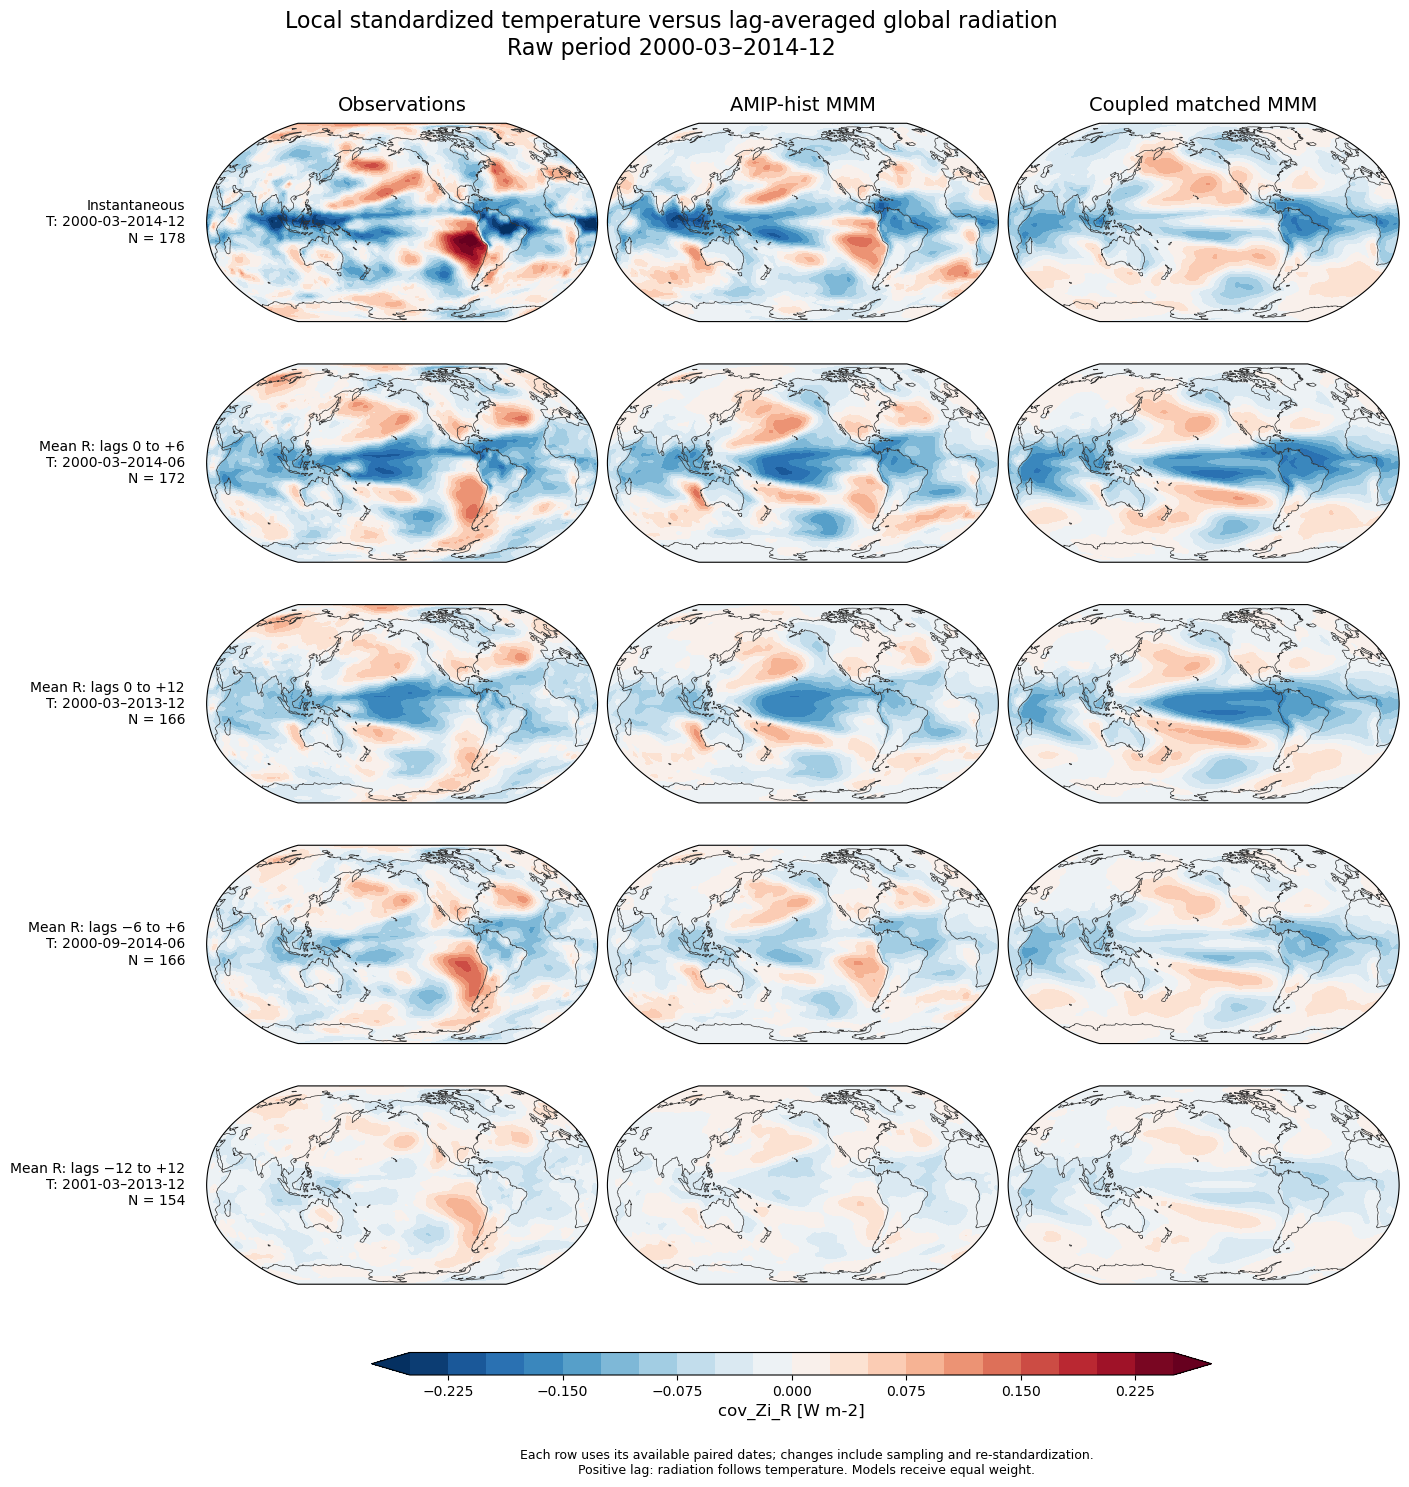

In [11]:
# %% 9. Default five-row comparison; change quantity/method without recomputing
lag_figure_path = lag_output_dir / "figures" / f"{lag_plot_quantity}_{lag_plot_method}.png" if lag_save_figure else None
fig_lag_comparison, axes_lag_comparison = plot_global_r_lag_comparison(lag_archive,
    quantity=lag_plot_quantity, plot_method=lag_plot_method, vlim=lag_vlim, percentile=lag_percentile,
    cmap=lag_cmap, figsize=lag_figsize, font_scale=lag_font_scale, savepath=lag_figure_path)
plt.show()

# Optional: plot quantity="cov_Zi_R_change", vlim=None to isolate lag averaging
# relative to each row's SAME-DATE instantaneous control (first row is zero).
# To compare all rows on the SAME dates, set lag_sample_mode="common" in cell 1
# and rerun cells 1–6 and 8–9. It saves separately; the per_case run is preserved.


0_to_3: 175 pairs; T at 2000-03–2014-09
1_to_3: 175 pairs; T at 2000-03–2014-09
Short lags: obs / ERA5_CERES
  Member 1/1 complete.
Short lags: amip_hist / BCC-CSM2-MR
  N: units absent; assuming W m-2.
  Member 1/1 complete.
Short lags: amip_hist / CAMS-CSM1-0
  N: units absent; assuming W m-2.
  Member 1/3 complete.
  Member 2/3 complete.
  Member 3/3 complete.
Short lags: amip_hist / CESM2
  N: units absent; assuming W m-2.
  Member 1/3 complete.
  Member 2/3 complete.
  Member 3/3 complete.
Short lags: amip_hist / CIESM
  N: units absent; assuming W m-2.
  Member 1/3 complete.
  Member 2/3 complete.
  Member 3/3 complete.
Short lags: amip_hist / CNRM-CM6-1
  N: units absent; assuming W m-2.
  Member 1/10 complete.
  Member 2/10 complete.
  Member 3/10 complete.
  Member 4/10 complete.
  Member 5/10 complete.
  Member 6/10 complete.
  Member 7/10 complete.
  Member 8/10 complete.
  Member 9/10 complete.
  Member 10/10 complete.
Short lags: amip_hist / CNRM-CM6-1-HR
  N: units absent

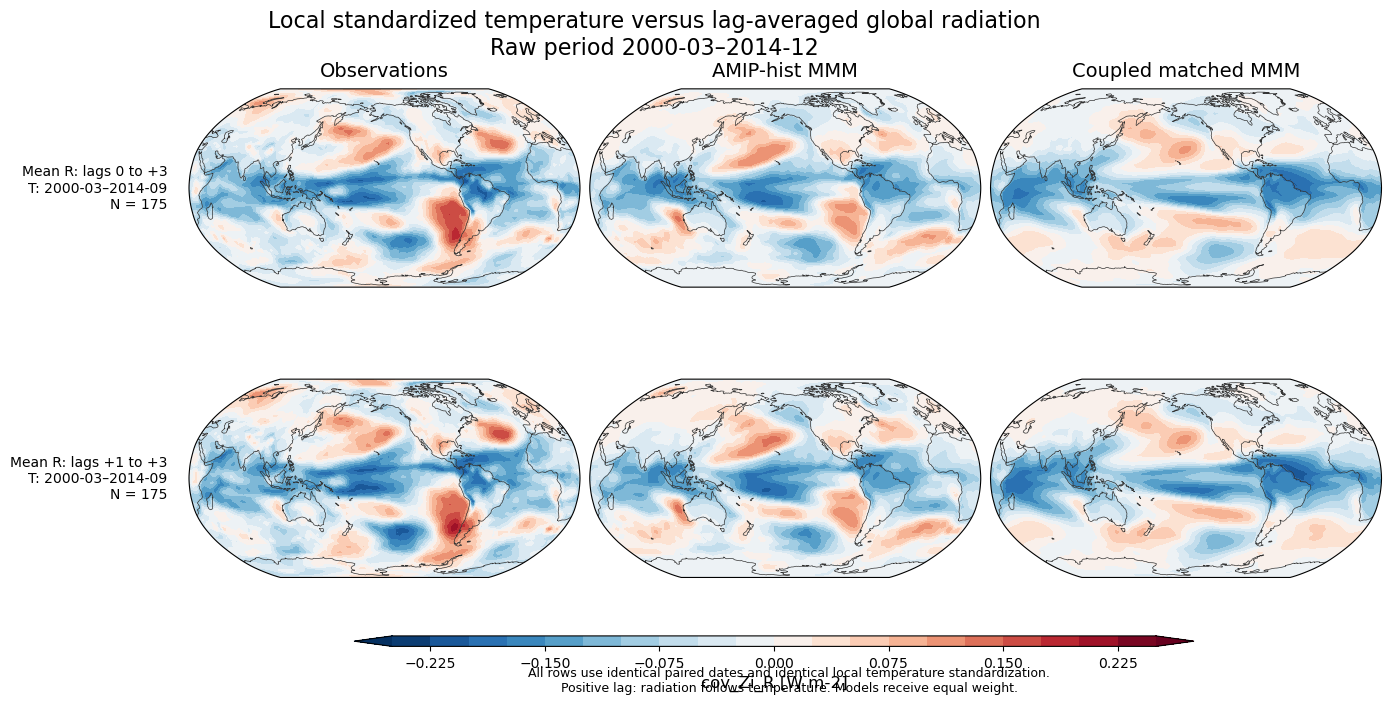

In [12]:
# %% 10. Standalone short-lag comparison: include versus exclude the current month
# Requires the original archive from cell 6 or 7, helpers from 2–3, and plot helper 8.
# In a fresh kernel: run 1–3, 7, 8, then this cell; also import your detrending function
# if calculating. The original five-row archive and its in-memory values stay intact.
short_output_dir = lag_archive_path.parent / "short_lags" / "run_01"
short_archive_path = short_output_dir / "global_r_short_lags.npy"
short_load_only = False                 # True: load this extension without reopening raw files.
short_cases = {"0_to_3": [0, 1, 2, 3], "1_to_3": [1, 2, 3]}
short_labels = {"0_to_3": "Mean R: lags 0 to +3", "1_to_3": "Mean R: lags +1 to +3"}


def calculate_short_global_r_comparison(reference, cases, labels, output_dir, preprocess,
                                       *, save=True, resume=True, preprocessing_tag="short_lags_v1"):
    """Reuse the saved grid/member inventory, but calculate new lag maps from raw fields."""
    import inspect
    if reference.get("schema") != "global_r_lag_comparison_v1" or not callable(preprocess):
        raise ValueError("Load the original lag archive and import your detrending function first.")
    output_dir = Path(output_dir); archive_path = output_dir / "global_r_short_lags.npy"
    months = reference["coordinates"]["raw_time"]
    lat, lon = [np.asarray(reference["coordinates"][d]) for d in ["lat", "lon"]]
    weights, support = reference["weights"], reference["map_support"]
    models, member_ids, info = reference["model_names"], reference["member_ids"], reference["quantity_info"]
    dates = lag_date_positions(months, cases, "common")
    for case, coordinate in dates.items():
        print(f"{case}: {coordinate['n_pairs']} pairs; T at {coordinate['time'][0]}–{coordinate['time'][-1]}")

    # Both requested cases retain the SAME 175 lag-zero months for this period.
    # Only R's averaging window differs. The zero-lag control and sigma_Ti must
    # therefore agree, and 4*Cov[0:3] = Cov[0] + 3*Cov[1:3] on these dates.
    try:
        preprocessing_source = inspect.getsource(preprocess)
    except (OSError, TypeError):
        preprocessing_source = "Unavailable: change preprocessing_tag when your function changes."
    settings = dict(reference["settings"], dates=dates, sample_mode="common", extension="short_lags_v1",
                    preprocessing_source=preprocessing_source, preprocessing_tag=preprocessing_tag)
    signature = lag_fingerprint(settings)
    if save and archive_path.exists():
        previous = np.load(archive_path, allow_pickle=True).item()
        if not resume or previous["signature"] != signature:
            raise ValueError("Short-lag settings changed or resume disabled; choose another short_output_dir.")
    member_values = {c: {e: {q: {} for q in info} for e in models} for c in cases}
    observations, sources = {}, {}

    # Read each source once per model, matching T/R member labels explicitly.
    # Only one member's monthly fields are materialized at a time. Complete-model
    # checkpoints allow restart; an interrupted model restarts from its first member.
    jobs = [("obs", "ERA5_CERES")] + [(e, m) for e in models for m in models[e]]
    for experiment, model in jobs:
        print(f"Short lags: {experiment} / {model}", flush=True)
        paths = {k: Path(v["path"]) for k, v in reference["sources"][experiment][model]["files"].items()}
        files = {k: {"path": str(p), "size": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for k, p in paths.items()}
        variables = {"T": "t2m", "R": "toa_net_all_mon"} if experiment == "obs" else {"T": "tas", "R": "N"}
        checkpoint = output_dir / "checkpoints" / experiment / f"{model}.npy"
        reused = save and checkpoint.exists()
        if reused:
            bundle = np.load(checkpoint, allow_pickle=True).item()
            if not resume or bundle["signature"] != signature or bundle["sources"] != files:
                raise ValueError(f"{checkpoint}: source/settings changed; choose another short_output_dir.")
            print("  Reusing completed model checkpoint.", flush=True)
        else:
            with xr.open_dataset(paths["T"]) as ds_T, xr.open_dataset(paths["R"]) as ds_R:
                T = lag_prepare_field(ds_T[variables["T"]], months, lat, lon, "T")
                R = lag_prepare_field(ds_R[variables["R"]], months, lat, lon, "R")
                ids = np.asarray(T.member.values).astype(str) if experiment == "obs" else np.asarray(member_ids[experiment][model]).astype(str)
                if not len(ids) or len(set(ids)) != len(ids) or set(ids) != set(T.member.values) or set(ids) != set(R.member.values):
                    raise ValueError(f"{model}: T/R member labels must match the saved inventory.")
                if experiment == "obs" and len(ids) != 1:
                    raise ValueError("Expected one observational realization.")
                T, R = T.sel(member=ids), R.sel(member=ids)
                collected = {c: {q: [] for q in info} for c in cases}
                for member in range(len(ids)):
                    result = calculate_global_r_lags(T.isel(member=member).values, R.isel(member=member).values,
                        weights, support, dates, preprocess, ddof=settings["ddof"])
                    for case in cases:
                        for quantity in info:
                            collected[case][quantity].append(result[case][quantity])
                    print(f"  Member {member+1}/{len(ids)} complete.", flush=True)
                bundle = {"values": {c: {q: np.stack(v) for q, v in d.items()} for c, d in collected.items()},
                    "member_ids": ids, "sources": files, "signature": signature,
                    "source_metadata": {k: dict(ds[variables[k]].attrs) for k, ds in [("T", ds_T), ("R", ds_R)]}}

        # Validate shapes before saving/reusing results. Observations lose their
        # artificial member axis; model values retain (member, lat, lon) or (member, time).
        for case, coordinate in dates.items():
            sizes = {"lat": len(lat), "lon": len(lon), "time": coordinate["n_pairs"]}
            for quantity, description in info.items():
                values = np.asarray(bundle["values"][case][quantity])
                expected_shape = (len(bundle["member_ids"]),) + tuple(sizes[d] for d in description["dims"])
                if values.shape != expected_shape or np.isinf(values).any():
                    raise ValueError(f"{model}/{case}/{quantity}: invalid shape or infinite values.")
                if experiment == "obs":
                    observations.setdefault(case, {})[quantity] = values[0]
                else:
                    member_values[case][experiment][quantity][model] = values
        if save and not reused:
            lag_save_bundle(checkpoint, bundle)
        sources.setdefault(experiment, {})[model] = {"files": files, "attributes": bundle["source_metadata"]}

    # Aggregate each diagnostic across members FIRST, then across models with
    # equal model weights. Do not calculate covariance from mean time series.
    model_means, MMM, model_counts, MMM_counts = [{c: {e: {} for e in models} for c in cases} for _ in range(4)]
    for case in cases:
        for experiment, names in models.items():
            for quantity in info:
                means, counts = {}, {}
                for model in names:
                    means[model], counts[model] = lag_finite_mean(member_values[case][experiment][quantity][model])
                model_means[case][experiment][quantity], model_counts[case][experiment][quantity] = means, counts
                MMM[case][experiment][quantity], MMM_counts[case][experiment][quantity] = lag_finite_mean(np.stack([means[m] for m in names]))
    archive = {"schema": reference["schema"], "member_values": member_values, "model_mean_values": model_means,
        "MMM_values": MMM, "observations": observations, "model_n_valid": model_counts, "MMM_n_valid": MMM_counts,
        "model_names": models, "member_ids": member_ids, "coordinates": {"lat": lat, "lon": lon, "raw_time": months, "cases": dates},
        "case_labels": {c: labels.get(c, c) for c in cases}, "quantity_info": info, "weights": weights, "map_support": support,
        "sources": sources, "settings": settings, "signature": signature,
        "metadata": dict(reference["metadata"], sampling="Identical paired dates and local T standardization for all short-lag cases",
                         extension="Include/exclude lag zero in monthly means; no ENSO adjustment or causal identification")}
    if save:
        lag_save_bundle(archive_path, archive, replace=archive_path.exists())
        print(f"Saved: {archive_path}")
    return archive


# Recompute only these two cases, or reload their own saved archive. In either
# case lag_archive still refers to the original five-row result; nothing is appended
# to or overwritten in that archive. No ENSO adjustment is introduced by this cell.
if short_load_only:
    short_lag_archive = np.load(short_archive_path, allow_pickle=True).item()  # Trusted file only.
else:
    short_lag_archive = calculate_short_global_r_comparison(lag_archive, short_cases, short_labels,
        short_output_dir, detrend_monthly_fast, save=lag_save, resume=lag_resume,
        preprocessing_tag=lag_preprocessing_tag)
short_member_values, short_model_mean_values = short_lag_archive["member_values"], short_lag_archive["model_mean_values"]
short_MMM_values, short_observations = short_lag_archive["MMM_values"], short_lag_archive["observations"]
short_figure_path = short_output_dir / "figures" / f"{lag_plot_quantity}_{lag_plot_method}.png" if lag_save_figure else None
fig_short_lags, axes_short_lags = plot_global_r_lag_comparison(short_lag_archive,
    quantity=lag_plot_quantity, plot_method=lag_plot_method, vlim=lag_vlim, percentile=lag_percentile,
    cmap=lag_cmap, figsize=(15, 7), font_scale=lag_font_scale, savepath=short_figure_path)
plt.show()

# Example: short_MMM_values["0_to_3"]["amip_hist"]["cov_Zi_R"]
# To load later, set short_load_only=True above (no raw files/detrending needed).
